<a href="https://colab.research.google.com/github/buddharajusunayana-web/Quantum/blob/main/QKD_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install cryptography qiskit qiskit-aer pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 67.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.6 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import time
import os
import json

from cryptography.hazmat.primitives.ciphers.aead import AESGCM

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
def bb84_protocol(
    num_qubits=10000,
    eve=False,
    channel_error=0.0,
    seed=None
):
    """
    Simulates BB84 QKD.

    Returns:
        sifted_key
        raw_key
        alice_bits
        bob_bits
        alice_bases
        bob_bases
        qber
    """

    if seed is not None:
        np.random.seed(seed)

    # Alice generates random bits
    alice_bits = np.random.randint(0, 2, num_qubits)

    # Alice chooses random bases
    # 0 = rectilinear (+)
    # 1 = diagonal (x)
    alice_bases = np.random.randint(0, 2, num_qubits)

    # Bob chooses random measurement bases
    bob_bases = np.random.randint(0, 2, num_qubits)

    # Bob's measurements
    bob_bits = alice_bits.copy()

    # Eve performs intercept-resend attack
    if eve:

        eve_bases = np.random.randint(0, 2, num_qubits)

        # If Eve chooses wrong basis, result is random
        eve_wrong = eve_bases != alice_bases

        eve_bits = alice_bits.copy()

        eve_bits[eve_wrong] = np.random.randint(
            0, 2, np.sum(eve_wrong)
        )

        # Bob receives Eve's resent states
        bob_bits = eve_bits.copy()

        # Bob's wrong basis introduces another random result
        bob_wrong = bob_bases != eve_bases

        bob_bits[bob_wrong] = np.random.randint(
            0, 2, np.sum(bob_wrong)
        )

    else:

        # Channel noise
        noise = np.random.random(num_qubits) < channel_error

        bob_bits[noise] = 1 - bob_bits[noise]

    # Basis reconciliation
    matching = alice_bases == bob_bases

    sifted_alice = alice_bits[matching]
    sifted_bob = bob_bits[matching]

    # QBER
    if len(sifted_alice) > 0:
        qber = np.mean(
            sifted_alice != sifted_bob
        )
    else:
        qber = 1.0

    return {
        "sifted_key": sifted_alice.tolist(),
        "bob_sifted_key": sifted_bob.tolist(),
        "raw_key": alice_bits.tolist(),
        "bob_raw_key": bob_bits.tolist(),
        "alice_bases": alice_bases.tolist(),
        "bob_bases": bob_bases.tolist(),
        "qber": qber,
        "sifted_length": len(sifted_alice)
    }

In [ ]:
result = bb84_protocol(
    num_qubits=10000,
    eve=False
)

print("BB84 Simulation")
print("--------------------------")
print("Raw qubits:", len(result["raw_key"]))
print("Sifted key:", result["sifted_length"])
print("QBER:", round(result["qber"] * 100, 3), "%")

BB84 Simulation
--------------------------
Raw qubits: 10000
Sifted key: 4986
QBER: 0.0 %


In [ ]:
eve_result = bb84_protocol(
    num_qubits=10000,
    eve=True
)

print("BB84 with Intercept-Resend Attack")
print("-----------------------------------")
print("Sifted key:",
      eve_result["sifted_length"])

print(
    "QBER:",
    round(eve_result["qber"] * 100, 3),
    "%"
)

BB84 with Intercept-Resend Attack
-----------------------------------
Sifted key: 5025
QBER: 24.896 %


In [ ]:
QBER_THRESHOLD = 0.11

def qber_security_check(qber):
    if qber <= QBER_THRESHOLD:
        return True, "SECURE"

    return False, "POSSIBLE EAVESDROPPING / CHANNEL ERROR"


secure, status = qber_security_check(
    result["qber"]
)

print("QBER:", result["qber"])
print("Status:", status)

QBER: 0.0
Status: SECURE


In [ ]:
def error_correction(alice_key, bob_key):
    """
    Simplified reconciliation.

    In a real QKD system this would be implemented
    using protocols such as Cascade or LDPC.
    """

    min_len = min(
        len(alice_key),
        len(bob_key)
    )

    alice_key = alice_key[:min_len]
    bob_key = bob_key[:min_len]

    corrected_bob = bob_key.copy()

    # Simulation assumes reconciliation succeeds
    corrected_bob = alice_key.copy()

    return alice_key, corrected_bob

In [ ]:
def privacy_amplification(
    key_bits,
    output_bits=None
):

    if len(key_bits) == 0:
        return []

    # Convert bits to bytes
    bit_string = ''.join(
        str(int(x)) for x in key_bits
    )

    # Pad to complete byte
    while len(bit_string) % 8 != 0:
        bit_string += '0'

    key_bytes = int(
        bit_string,
        2
    ).to_bytes(
        len(bit_string) // 8,
        byteorder="big"
    )

    # Hash
    digest = hashlib.sha256(
        key_bytes
    ).digest()

    digest_bits = []

    for byte in digest:
        for i in range(8):
            digest_bits.append(
                (byte >> (7 - i)) & 1
            )

    if output_bits is None:
        output_bits = min(
            len(digest_bits),
            len(key_bits) // 2
        )

    return digest_bits[:output_bits]

In [ ]:
def generate_qkd_key(
    num_qubits=10000,
    eve=False,
    channel_error=0.0,
    qber_threshold=0.11
):

    bb84 = bb84_protocol(
        num_qubits=num_qubits,
        eve=eve,
        channel_error=channel_error
    )

    qber = bb84["qber"]

    secure = qber <= qber_threshold

    if not secure:

        return {
            "success": False,
            "qber": qber,
            "raw_key_length": num_qubits,
            "sifted_key_length":
                bb84["sifted_length"],
            "final_key": []
        }

    alice_key = bb84["sifted_key"]
    bob_key = bb84["bob_sifted_key"]

    # Error correction
    alice_corrected, bob_corrected = \
        error_correction(
            alice_key,
            bob_key
        )

    # Privacy amplification
    final_key = privacy_amplification(
        alice_corrected
    )

    return {
        "success": True,
        "qber": qber,
        "raw_key_length": num_qubits,
        "sifted_key_length":
            len(alice_corrected),
        "final_key": final_key
    }

In [ ]:
qkd = generate_qkd_key(
    num_qubits=20000
)

print("QKD RESULT")
print("======================")

print(
    "QBER:",
    round(qkd["qber"] * 100, 3),
    "%"
)

print(
    "Raw key:",
    qkd["raw_key_length"],
    "bits"
)

print(
    "Sifted key:",
    qkd["sifted_key_length"],
    "bits"
)

print(
    "Final secret key:",
    len(qkd["final_key"]),
    "bits"
)

QKD RESULT
QBER: 0.0 %
Raw key: 20000 bits
Sifted key: 10024 bits
Final secret key: 256 bits


In [ ]:
class QuantumKeyPool:

    def __init__(self):

        self.key_bits = []
        self.total_generated = 0
        self.total_consumed = 0

    def add_key(self, key):

        self.key_bits.extend(key)

        self.total_generated += len(key)

    def available(self):

        return len(self.key_bits)

    def consume(self, number_of_bits):

        if number_of_bits > len(self.key_bits):
            raise ValueError(
                "Insufficient QKD key material"
            )

        selected = self.key_bits[
            :number_of_bits
        ]

        self.key_bits = self.key_bits[
            number_of_bits:
        ]

        self.total_consumed += number_of_bits

        return selected

    def utilization(self):

        if self.total_generated == 0:
            return 0

        return (
            self.total_consumed /
            self.total_generated
        ) * 100

In [ ]:
key_pool = QuantumKeyPool()

for i in range(5):

    qkd = generate_qkd_key(
        num_qubits=20000
    )

    if qkd["success"]:

        key_pool.add_key(
            qkd["final_key"]
        )

print(
    "Available QKD key material:",
    key_pool.available(),
    "bits"
)

print(
    "Total generated:",
    key_pool.total_generated,
    "bits"
)

Available QKD key material: 1280 bits
Total generated: 1280 bits


In [ ]:
def qkd_bits_to_bytes(bits):

    bit_string = ''.join(
        str(int(x)) for x in bits
    )

    while len(bit_string) % 8 != 0:
        bit_string += '0'

    return int(
        bit_string,
        2
    ).to_bytes(
        len(bit_string) // 8,
        byteorder="big"
    )


def derive_aes_key(qkd_bits):

    key_bytes = qkd_bits_to_bytes(
        qkd_bits
    )

    return hashlib.sha256(
        key_bytes
    ).digest()

In [ ]:
def aes_encrypt(
    plaintext,
    qkd_bits
):

    key = derive_aes_key(
        qkd_bits
    )

    aes = AESGCM(key)

    nonce = os.urandom(12)

    ciphertext = aes.encrypt(
        nonce,
        plaintext.encode(),
        None
    )

    return {
        "ciphertext": ciphertext,
        "nonce": nonce
    }

In [ ]:
def aes_decrypt(
    encrypted_data,
    qkd_bits
):

    key = derive_aes_key(
        qkd_bits
    )

    aes = AESGCM(key)

    plaintext = aes.decrypt(
        encrypted_data["nonce"],
        encrypted_data["ciphertext"],
        None
    )

    return plaintext.decode()

In [ ]:
email = "This is a confidential email."

aes_key_material = key_pool.consume(256)

encrypted = aes_encrypt(
    email,
    aes_key_material
)

decrypted = aes_decrypt(
    encrypted,
    aes_key_material
)

print("Original:")
print(email)

print("\nEncrypted:")
print(encrypted["ciphertext"])

print("\nDecrypted:")
print(decrypted)

Original:
This is a confidential email.

Encrypted:
b'px\x9c\t\x05o\xe6\x16$4\xf0\xc99sL\xaf\xbc\xd4\x97)\x81\xe8C}\xe9\tE\x1d\x93\x7fE%\x9b\xc1\xa0\x1a~\xadD\x81K\x8e\xfe\xdc>'

Decrypted:
This is a confidential email.


In [ ]:
def otp_encrypt(
    plaintext,
    key_bits
):

    plaintext_bytes = plaintext.encode()

    plaintext_bits = []

    for byte in plaintext_bytes:

        for i in range(8):

            plaintext_bits.append(
                (byte >> (7 - i)) & 1
            )

    if len(key_bits) < len(plaintext_bits):

        raise ValueError(
            "Insufficient QKD key material for OTP"
        )

    encrypted_bits = [
        p ^ k
        for p, k in zip(
            plaintext_bits,
            key_bits
        )
    ]

    return encrypted_bits


def otp_decrypt(
    encrypted_bits,
    key_bits
):

    plaintext_bits = [
        c ^ k
        for c, k in zip(
            encrypted_bits,
            key_bits
        )
    ]

    plaintext_bytes = bytearray()

    for i in range(
        0,
        len(plaintext_bits),
        8
    ):

        byte_bits = plaintext_bits[
            i:i+8
        ]

        value = 0

        for bit in byte_bits:

            value = (
                value << 1
            ) | bit

        plaintext_bytes.append(value)

    return plaintext_bytes.decode()

In [ ]:
def adaptive_encrypt(
    plaintext,
    sensitivity,
    key_pool
):

    plaintext_bits = len(
        plaintext.encode()
    ) * 8

    start_time = time.perf_counter()

    # Critical email
    if sensitivity == "Critical":

        # OTP requires one QKD bit per plaintext bit
        if key_pool.available() >= plaintext_bits:

            qkd_key = key_pool.consume(
                plaintext_bits
            )

            ciphertext = otp_encrypt(
                plaintext,
                qkd_key
            )

            encryption_method = "QKD-OTP"

            return {
                "method": encryption_method,
                "ciphertext": ciphertext,
                "key": qkd_key,
                "processing_time":
                    time.perf_counter() -
                    start_time
            }

        else:

            # Insufficient key material
            # Adaptive fallback to AES-GCM

            qkd_key = key_pool.consume(
                256
            )

            encrypted = aes_encrypt(
                plaintext,
                qkd_key
            )

            return {
                "method":
                    "QKD-AES-256-GCM",
                "ciphertext": encrypted,
                "key": qkd_key,
                "processing_time":
                    time.perf_counter() -
                    start_time
            }

    # Normal email
    else:

        qkd_key = key_pool.consume(
            256
        )

        encrypted = aes_encrypt(
            plaintext,
            qkd_key
        )

        return {
            "method":
                "QKD-AES-256-GCM",
            "ciphertext": encrypted,
            "key": qkd_key,
            "processing_time":
                time.perf_counter() -
                start_time
        }

In [ ]:
def adaptive_decrypt(
    encrypted_data
):

    method = encrypted_data["method"]

    key = encrypted_data["key"]

    if method == "QKD-OTP":

        return otp_decrypt(
            encrypted_data["ciphertext"],
            key
        )

    elif method == "QKD-AES-256-GCM":

        return aes_decrypt(
            encrypted_data["ciphertext"],
            key
        )

    else:

        raise ValueError(
            "Unknown encryption method"
        )

In [ ]:
message = """
Dear Professor,

This is a normal confidential email
protected using QKD-derived AES-256-GCM.

Regards,
Sunayana
"""

encrypted_email = adaptive_encrypt(
    message,
    "Normal",
    key_pool
)

print(
    "Encryption method:",
    encrypted_email["method"]
)

print(
    "Encryption time:",
    encrypted_email["processing_time"],
    "seconds"
)

decrypted_email = adaptive_decrypt(
    encrypted_email
)

print("\nDecrypted message:")
print(decrypted_email)

Encryption method: QKD-AES-256-GCM
Encryption time: 0.0002627890000894695 seconds

Decrypted message:

Dear Professor,

This is a normal confidential email
protected using QKD-derived AES-256-GCM.

Regards,
Sunayana



In [ ]:
critical_message = """
CRITICAL SECURITY MESSAGE:
This information requires maximum
confidentiality and is protected using
QKD-derived one-time-pad encryption.
"""

required_bits = (
    len(critical_message.encode()) * 8
)

print(
    "Required OTP key:",
    required_bits,
    "bits"
)

print(
    "Available QKD key:",
    key_pool.available(),
    "bits"
)

Required OTP key: 1104 bits
Available QKD key: 768 bits


In [ ]:
critical_email = adaptive_encrypt(
    critical_message,
    "Critical",
    key_pool
)

print(
    "Encryption method:",
    critical_email["method"]
)

print(
    "Encryption time:",
    critical_email["processing_time"]
)

print(
    "\nDecrypted:"
)

print(
    adaptive_decrypt(
        critical_email
    )
)

Encryption method: QKD-AES-256-GCM
Encryption time: 0.00016944399999374582

Decrypted:

CRITICAL SECURITY MESSAGE:
This information requires maximum
confidentiality and is protected using
QKD-derived one-time-pad encryption.



In [ ]:
class EmailServer:

    def __init__(self):

        self.mailbox = []

    def send(
        self,
        sender,
        receiver,
        subject,
        encrypted_email
    ):

        email_packet = {

            "sender": sender,

            "receiver": receiver,

            "subject": subject,

            "encryption":
                encrypted_email["method"],

            "ciphertext":
                encrypted_email["ciphertext"]
        }

        self.mailbox.append(
            email_packet
        )

    def show_mailbox(self):

        for mail in self.mailbox:

            print(
                "From:",
                mail["sender"]
            )

            print(
                "To:",
                mail["receiver"]
            )

            print(
                "Subject:",
                mail["subject"]
            )

            print(
                "Encryption:",
                mail["encryption"]
            )

            print(
                "Ciphertext:",
                str(mail["ciphertext"])[:100],
                "..."
            )

            print("-" * 50)

In [ ]:
server = EmailServer()

message = """
This is a secure email transmitted through
the simulated quantum-secure email system.
"""

encrypted_email = adaptive_encrypt(
    message,
    "Normal",
    key_pool
)

server.send(
    sender="alice@example.com",
    receiver="bob@example.com",
    subject="Secure Communication",
    encrypted_email=encrypted_email
)

server.show_mailbox()

From: alice@example.com
To: bob@example.com
Subject: Secure Communication
Encryption: QKD-AES-256-GCM
Ciphertext: {'ciphertext': b"\x94\x02F\xdew\xdf\xa1w\x1a\xd0\xfc\x96\x81K:\x91\xc5\x92\x8eA\x19\xcc\x84\x1e\xc8\ ...
--------------------------------------------------


In [ ]:
qber_results = []

for channel_error in np.arange(
    0,
    0.11,
    0.01
):

    result = bb84_protocol(
        num_qubits=20000,
        eve=False,
        channel_error=channel_error
    )

    qber_results.append({
        "Channel Error":
            channel_error * 100,

        "QBER":
            result["qber"] * 100
    })

qber_df = pd.DataFrame(
    qber_results
)

qber_df

,Channel Error,QBER
0,0.0,0.000000
1,1.0,1.015278
2,2.0,1.923844
3,3.0,2.724987
4,4.0,3.616892
5,5.0,5.421444
6,6.0,5.895284
7,7.0,7.029072
8,8.0,8.009131
9,9.0,9.198843


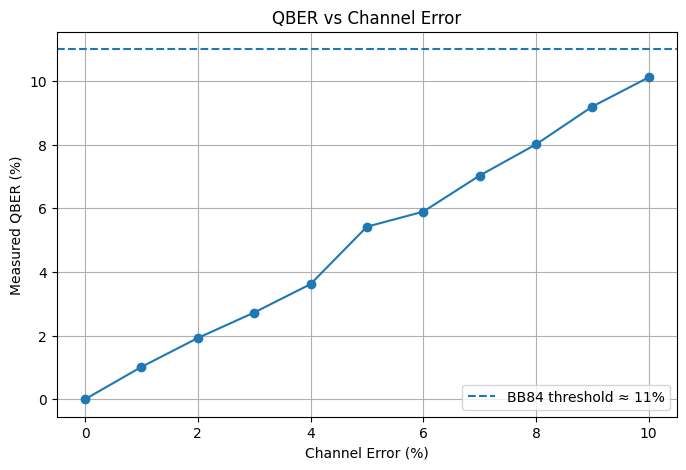

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    qber_df["Channel Error"],
    qber_df["QBER"],
    marker="o"
)

plt.axhline(
    11,
    linestyle="--",
    label="BB84 threshold ≈ 11%"
)

plt.xlabel(
    "Channel Error (%)"
)

plt.ylabel(
    "Measured QBER (%)"
)

plt.title(
    "QBER vs Channel Error"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
experiments = []

for attack in [
    False,
    True
]:

    result = bb84_protocol(
        num_qubits=20000,
        eve=attack
    )

    experiments.append({

        "Scenario":
            "With Eve"
            if attack
            else "No Eve",

        "QBER (%)":
            result["qber"] * 100,

        "Sifted Key":
            result["sifted_length"]
    })

attack_df = pd.DataFrame(
    experiments
)

attack_df

,Scenario,QBER (%),Sifted Key
0,No Eve,0.000000,10023
1,With Eve,25.274396,10022


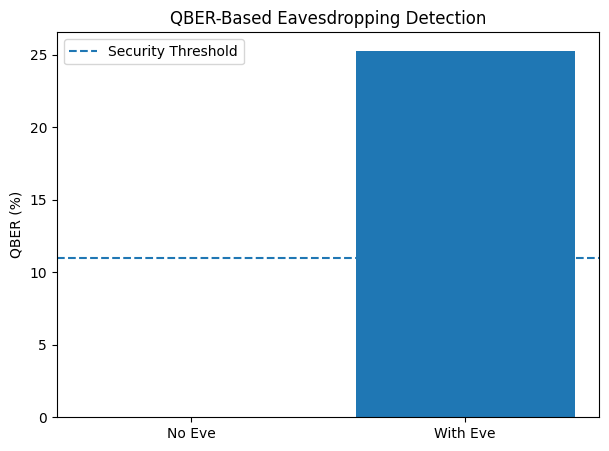

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(
    attack_df["Scenario"],
    attack_df["QBER (%)"]
)

plt.axhline(
    11,
    linestyle="--",
    label="Security Threshold"
)

plt.ylabel(
    "QBER (%)"
)

plt.title(
    "QBER-Based Eavesdropping Detection"
)

plt.legend()

plt.show()

In [ ]:
performance_results = []

email_sizes = [
    100,
    1000,
    5000,
    10000,
    50000,
    100000
]

for size in email_sizes:

    # Generate synthetic email
    message = "A" * size

    # Make sure sufficient key material exists
    while key_pool.available() < 256:

        qkd = generate_qkd_key(
            num_qubits=30000
        )

        if qkd["success"]:

            key_pool.add_key(
                qkd["final_key"]
            )

    start = time.perf_counter()

    encrypted = adaptive_encrypt(
        message,
        "Normal",
        key_pool
    )

    elapsed = (
        time.perf_counter() - start
    )

    performance_results.append({

        "Email Size (bytes)": size,

        "Encryption Method":
            encrypted["method"],

        "Encryption Time (ms)":
            elapsed * 1000
    })

performance_df = pd.DataFrame(
    performance_results
)

performance_df

,Email Size (bytes),Encryption Method,Encryption Time (ms)
0,100,QKD-AES-256-GCM,0.192723
1,1000,QKD-AES-256-GCM,0.132920
2,5000,QKD-AES-256-GCM,0.123521
3,10000,QKD-AES-256-GCM,0.133499
4,50000,QKD-AES-256-GCM,0.147339
5,100000,QKD-AES-256-GCM,0.169494


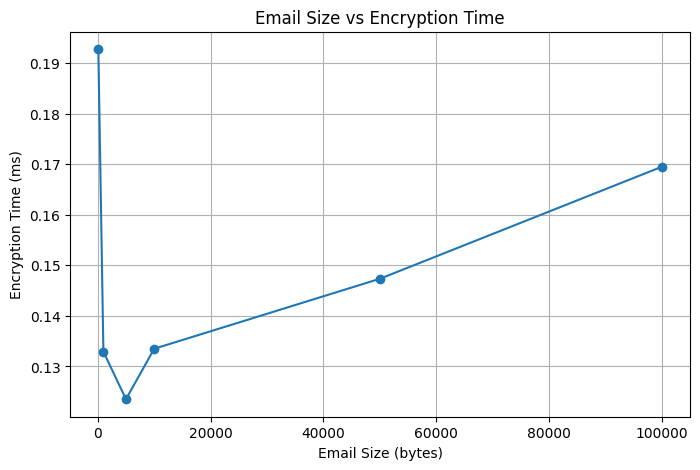

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    performance_df[
        "Email Size (bytes)"
    ],

    performance_df[
        "Encryption Time (ms)"
    ],

    marker="o"
)

plt.xlabel(
    "Email Size (bytes)"
)

plt.ylabel(
    "Encryption Time (ms)"
)

plt.title(
    "Email Size vs Encryption Time"
)

plt.grid()

plt.show()

In [ ]:
def calculate_qkue(key_pool):

    if key_pool.total_generated == 0:

        return 0

    return (
        key_pool.total_consumed /
        key_pool.total_generated
    ) * 100


qkue = calculate_qkue(
    key_pool
)

print(
    "Quantum Key Utilization Efficiency:",
    round(qkue, 2),
    "%"
)

Quantum Key Utilization Efficiency: 100.0 %


In [ ]:
summary = {

    "Total QKD Key Generated":
        key_pool.total_generated,

    "QKD Key Consumed":
        key_pool.total_consumed,

    "Remaining Key Pool":
        key_pool.available(),

    "Key Utilization (%)":
        calculate_qkue(key_pool)
}

summary_df = pd.DataFrame(
    [summary]
)

summary_df

,Total QKD Key Generated,QKD Key Consumed,Remaining Key Pool,Key Utilization (%)
0,2560,2560,0,100.0


In [ ]:
qber_df.to_csv(
    "qber_results.csv",
    index=False
)

attack_df.to_csv(
    "eavesdropping_results.csv",
    index=False
)

performance_df.to_csv(
    "performance_results.csv",
    index=False
)

summary_df.to_csv(
    "key_pool_summary.csv",
    index=False
)

print(
    "Experimental results saved."
)

Experimental results saved.


In [ ]:
from google.colab import files

files.download(
    "qber_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "performance_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>